In [50]:
import pandas as pd

In [51]:
# 读取数据文件
data = pd.read_csv('car.data', header=None)

In [41]:
column_names = ['buying','maint', 'doors', 'persons', 'lug_boot','safety', 'class']
data = pd.read_csv('car.data', names=column_names, sep=',')

In [53]:
# 查看数据形状
print("数据形状:", data.shape)
# 查看前5行数据
print("数据前5行:\n", data.head())
# 查看数据类型
print("数据类型:\n", data.dtypes)

数据形状: (1728, 7)
数据前5行:
        0      1  2  3      4     5      6
0  vhigh  vhigh  2  2  small   low  unacc
1  vhigh  vhigh  2  2  small   med  unacc
2  vhigh  vhigh  2  2  small  high  unacc
3  vhigh  vhigh  2  2    med   low  unacc
4  vhigh  vhigh  2  2    med   med  unacc
数据类型:
 0    object
1    object
2    object
3    object
4    object
5    object
6    object
dtype: object


In [54]:
print(data.isnull().sum())

0    0
1    0
2    0
3    0
4    0
5    0
6    0
dtype: int64


In [55]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

# 读取数据
column_names = ['buying','maint', 'doors', 'persons', 'lug_boot','safety', 'class']
data = pd.read_csv('car.data', names=column_names, sep=',')


# 对所有特征和目标变量进行标签编码
label_encoders = {}
for col in data.columns:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col])
    label_encoders[col] = le
# 提取特征和目标变量
X = data.drop('class', axis=1)
y = data['class']

# 划分数据集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("训练集特征形状:", X_train.shape)
print("训练集标签形状:", y_train.shape)
print("测试集特征形状:", X_test.shape)
print("测试集标签形状:", y_test.shape)

训练集特征形状: (1382, 6)
训练集标签形状: (1382,)
测试集特征形状: (346, 6)
测试集标签形状: (346,)


In [56]:
from imblearn.over_sampling import RandomOverSampler
from sklearn.model_selection import train_test_split
import pandas as pd
from sklearn.preprocessing import LabelEncoder
# 过采样
ros = RandomOverSampler(random_state=42)
X_train_resampled, y_train_resampled = ros.fit_resample(X_train, y_train)

In [57]:
X_train.info()
y.value_counts()

<class 'pandas.core.frame.DataFrame'>
Index: 1382 entries, 107 to 1126
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   buying    1382 non-null   int32
 1   maint     1382 non-null   int32
 2   doors     1382 non-null   int32
 3   persons   1382 non-null   int32
 4   lug_boot  1382 non-null   int32
 5   safety    1382 non-null   int32
dtypes: int32(6)
memory usage: 43.2 KB


class
2    1210
0     384
1      69
3      65
Name: count, dtype: int64

In [58]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import RandomOverSampler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report

# 读取数据
column_names = ['buying','maint', 'doors', 'persons', 'lug_boot','safety', 'class']
data = pd.read_csv('car.data', names=column_names, sep=',')

# 检查数据前几行及数据类型
print("数据前几行：")
print(data.head())

# 对所有特征和目标变量进行标签编码
label_encoders = {}
for col in data.columns:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col])
    label_encoders[col] = le
# 对目标变量class进行标签编码
le_target = LabelEncoder()
data_encoded['class'] = le_target.fit_transform(data_encoded['class'])

# 检查编码后的数据特征
print("编码后数据前几行：")
print(data_encoded.head())

# 提取特征和目标变量
X = data_encoded.drop('class', axis=1)
y = data_encoded['class']

# 划分训练集与测试集 (8:2)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 过采样
ros = RandomOverSampler(random_state=42)
X_train_resampled, y_train_resampled = ros.fit_resample(X_train, y_train)

# 逻辑回归模型
logreg = LogisticRegression(random_state=42)
logreg.fit(X_train_resampled, y_train_resampled)
y_pred_logreg = logreg.predict(X_test)
print("逻辑回归模型准确率:", accuracy_score(y_test, y_pred_logreg))
print("逻辑回归模型分类报告:\n", classification_report(y_test, y_pred_logreg))

数据前几行：
  buying  maint doors persons lug_boot safety  class
0  vhigh  vhigh     2       2    small    low  unacc
1  vhigh  vhigh     2       2    small    med  unacc
2  vhigh  vhigh     2       2    small   high  unacc
3  vhigh  vhigh     2       2      med    low  unacc
4  vhigh  vhigh     2       2      med    med  unacc
编码后数据前几行：
   buying  maint  lug_boot  safety  class  doors_2  doors_3  doors_4  \
0       3      3         2       1      2     True    False    False   
1       3      3         2       2      2     True    False    False   
2       3      3         2       0      2     True    False    False   
3       3      3         1       1      2     True    False    False   
4       3      3         1       2      2     True    False    False   

   doors_5more  persons_2  persons_4  persons_more  
0        False       True      False         False  
1        False       True      False         False  
2        False       True      False         False  
3        False      

In [16]:
# SVM模型
svm = SVC(random_state=42)
svm.fit(X_train_resampled, y_train_resampled)
y_pred_svm = svm.predict(X_test)
print("SVM模型准确率:", accuracy_score(y_test, y_pred_svm))
print("SVM模型分类报告:\n", classification_report(y_test, y_pred_svm))

# 决策树模型
dtree = DecisionTreeClassifier(random_state=42)
dtree.fit(X_train_resampled, y_train_resampled)
y_pred_dtree = dtree.predict(X_test)
print("决策树模型准确率:", accuracy_score(y_test, y_pred_dtree))
print("决策树模型分类报告:\n", classification_report(y_test, y_pred_dtree))

SVM模型准确率: 0.8901734104046243
SVM模型分类报告:
               precision    recall  f1-score   support

           0       0.74      0.84      0.79        83
           1       0.46      1.00      0.63        11
           2       1.00      0.89      0.94       235
           3       1.00      1.00      1.00        17

    accuracy                           0.89       346
   macro avg       0.80      0.93      0.84       346
weighted avg       0.92      0.89      0.90       346

决策树模型准确率: 0.9653179190751445
决策树模型分类报告:
               precision    recall  f1-score   support

           0       0.96      0.89      0.92        83
           1       0.62      0.91      0.74        11
           2       0.99      1.00      0.99       235
           3       1.00      0.94      0.97        17

    accuracy                           0.97       346
   macro avg       0.89      0.93      0.91       346
weighted avg       0.97      0.97      0.97       346



## 模型评估与性能对比

In [17]:
# 随机森林模型
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train_resampled, y_train_resampled)
y_pred_rf = rf.predict(X_test)
print("随机森林模型准确率:", accuracy_score(y_test, y_pred_rf))
print("随机森林模型分类报告:\n", classification_report(y_test, y_pred_rf))

随机森林模型准确率: 0.930635838150289
随机森林模型分类报告:
               precision    recall  f1-score   support

           0       0.87      0.83      0.85        83
           1       0.62      0.91      0.74        11
           2       0.97      0.97      0.97       235
           3       0.88      0.88      0.88        17

    accuracy                           0.93       346
   macro avg       0.84      0.90      0.86       346
weighted avg       0.93      0.93      0.93       346



In [18]:
# 朴素贝叶斯模型
nb = GaussianNB()
nb.fit(X_train_resampled, y_train_resampled)
y_pred_nb = nb.predict(X_test)
print("朴素贝叶斯模型准确率:", accuracy_score(y_test, y_pred_nb))
print("朴素贝叶斯模型分类报告:\n", classification_report(y_test, y_pred_nb))

朴素贝叶斯模型准确率: 0.5202312138728323
朴素贝叶斯模型分类报告:
               precision    recall  f1-score   support

           0       0.28      0.37      0.32        83
           1       0.19      0.55      0.29        11
           2       1.00      0.54      0.70       235
           3       0.22      1.00      0.36        17

    accuracy                           0.52       346
   macro avg       0.42      0.61      0.42       346
weighted avg       0.76      0.52      0.58       346



In [19]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import RandomOverSampler
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, classification_report

# XGBoost模型
xgb_model = XGBClassifier(random_state=42)
xgb_model.fit(X_train_resampled, y_train_resampled)
y_pred_xgb = xgb_model.predict(X_test)
print("XGBoost模型准确率:", accuracy_score(y_test, y_pred_xgb))
print("XGBoost模型分类报告:\n", classification_report(y_test, y_pred_xgb))



XGBoost模型准确率: 0.9797687861271677
XGBoost模型分类报告:
               precision    recall  f1-score   support

           0       1.00      0.92      0.96        83
           1       0.61      1.00      0.76        11
           2       1.00      1.00      1.00       235
           3       1.00      1.00      1.00        17

    accuracy                           0.98       346
   macro avg       0.90      0.98      0.93       346
weighted avg       0.99      0.98      0.98       346



In [20]:
# LightGBM模型
lgbm_model = LGBMClassifier(random_state=42)
lgbm_model.fit(X_train_resampled, y_train_resampled)
y_pred_lgbm = lgbm_model.predict(X_test)
print("LightGBM模型准确率:", accuracy_score(y_test, y_pred_lgbm))
print("LightGBM模型分类报告:\n", classification_report(y_test, y_pred_lgbm))

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000045 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 28
[LightGBM] [Info] Number of data points in the train set: 3900, number of used features: 11
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
LightGBM模型准确率: 0.9826589595375722
LightGBM模型分类报告:
               precision    recall  f1-score   support

           0       0.99      0.94      0.96        83
           1       0.73      1.00      0.85        11
           2       1.00      1.00      1.00       235
           3       1.00      0.94      0.97        17

    accuracy                        

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000046 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 28
[LightGBM] [Info] Number of data points in the train set: 3900, number of used features: 11
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


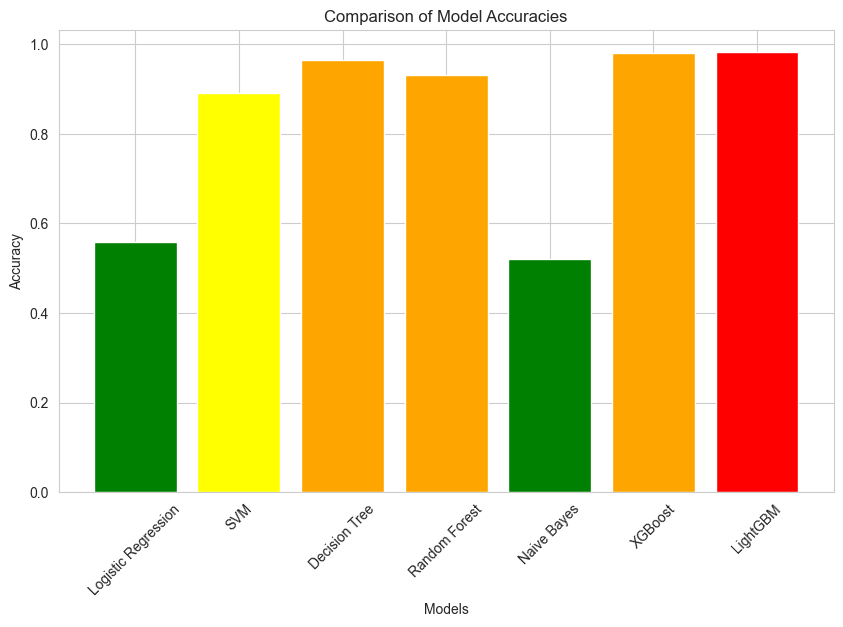

In [31]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import RandomOverSampler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# 读取数据
column_names = ['buying','maint', 'doors', 'persons', 'lug_boot','safety', 'class']
data = pd.read_csv('car.data', names=column_names, sep=',')
label_encoders = {}
for col in data.columns:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col])
    label_encoders[col] = le

# 对目标变量class进行标签编码
le_target = LabelEncoder()
data_encoded['class'] = le_target.fit_transform(data_encoded['class'])

# 提取特征和目标变量
X = data_encoded.drop('class', axis=1)
y = data_encoded['class']

# 划分训练集与测试集 (8:2)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 过采样
ros = RandomOverSampler(random_state=42)
X_train_resampled, y_train_resampled = ros.fit_resample(X_train, y_train)

# 逻辑回归模型
logreg = LogisticRegression(random_state=42)
logreg.fit(X_train_resampled, y_train_resampled)
y_pred_logreg = logreg.predict(X_test)
accuracy_logreg = accuracy_score(y_test, y_pred_logreg)

# SVM模型
svm = SVC(random_state=42)
svm.fit(X_train_resampled, y_train_resampled)
y_pred_svm = svm.predict(X_test)
accuracy_svm = accuracy_score(y_test, y_pred_svm)

# 决策树模型
dtree = DecisionTreeClassifier(random_state=42)
dtree.fit(X_train_resampled, y_train_resampled)
y_pred_dtree = dtree.predict(X_test)
accuracy_dtree = accuracy_score(y_test, y_pred_dtree)

# 随机森林模型
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train_resampled, y_train_resampled)
y_pred_rf = rf.predict(X_test)
accuracy_rf = accuracy_score(y_test, y_pred_rf)

# 朴素贝叶斯模型
nb = GaussianNB()
nb.fit(X_train_resampled, y_train_resampled)
y_pred_nb = nb.predict(X_test)
accuracy_nb = accuracy_score(y_test, y_pred_nb)

# XGBoost模型
xgb_model = XGBClassifier(random_state=42)
xgb_model.fit(X_train_resampled, y_train_resampled)
y_pred_xgb = xgb_model.predict(X_test)
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)

# LightGBM模型
lgbm_model = LGBMClassifier(random_state=42)
lgbm_model.fit(X_train_resampled, y_train_resampled)
y_pred_lgbm = lgbm_model.predict(X_test)
accuracy_lgbm = accuracy_score(y_test, y_pred_lgbm)

# 模型名称和对应的准确率
models = ['Logistic Regression', 'SVM', 'Decision Tree', 'Random Forest', 'Naive Bayes', 'XGBoost', 'LightGBM']
accuracies = [accuracy_logreg, accuracy_svm, accuracy_dtree, accuracy_rf, accuracy_nb, accuracy_xgb, accuracy_lgbm]

# 根据准确率设置颜色
colors = []
for acc in accuracies:
    if acc < 0.6:
        colors.append('green')
    elif 0.6 <= acc < 0.8:
        colors.append('yellowgreen')
    elif 0.8 <= acc < 0.9:
        colors.append('yellow')
    else:
        colors.append('orange')
# 确定最优模型索引
max_index = accuracies.index(max(accuracies))

# 高亮标注表现最佳的模型
colors[max_index] = 'red'
# 可视化
sns.set_style("whitegrid")
plt.figure(figsize=(10, 6))
plt.bar(models, accuracies, color=colors)
plt.xlabel('Models')
plt.ylabel('Accuracy')
plt.title('Comparison of Model Accuracies')
plt.xticks(rotation=45)
plt.show()

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000055 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 21
[LightGBM] [Info] Number of data points in the train set: 3900, number of used features: 6
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


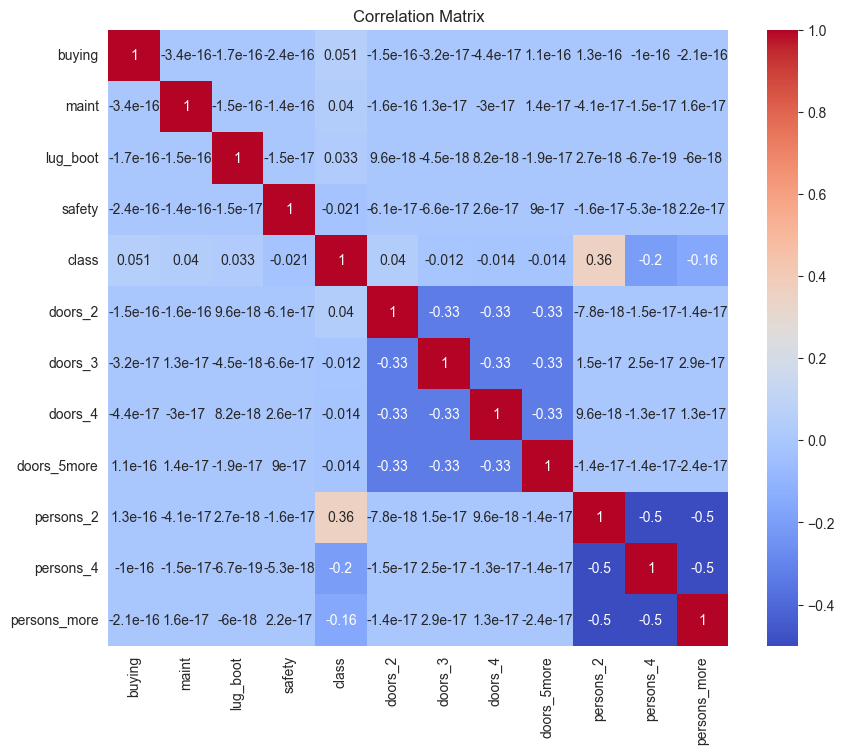

In [30]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import RandomOverSampler
from lightgbm import LGBMClassifier
import shap
import matplotlib.pyplot as plt
from sklearn.inspection import PartialDependenceDisplay
import seaborn as sns
from scipy.stats import chi2_contingency

# 读取数据
column_names = ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class']
data = pd.read_csv('car.data', names=column_names, sep=',')

# 对所有特征和目标变量进行标签编码
label_encoders = {}
for col in data.columns:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col])
    label_encoders[col] = le

# 提取特征和目标变量
X = data.drop('class', axis=1)
y = data['class']

# 划分训练集与测试集 (8:2)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 过采样
ros = RandomOverSampler(random_state=42)
X_train_resampled, y_train_resampled = ros.fit_resample(X_train, y_train)

# LightGBM 模型
lgbm_model = LGBMClassifier(random_state=42)
lgbm_model.fit(X_train_resampled, y_train_resampled)

from sklearn.inspection import PartialDependenceDisplay

import seaborn as sns

# 计算特征相关系数矩阵
correlation_matrix = data_encoded.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

In [32]:
# 类别特征与目标变量的关系（使用交叉表和卡方检验）
for col in X.columns:
    cross_tab = pd.crosstab(data[col], data['class'])
    chi2, p, dof, expected = chi2_contingency(cross_tab)
    print(f"Chi-square statistic for {col} and class: {chi2}, p-value: {p}")

Chi-square statistic for buying and class: 189.24300964187327, p-value: 5.9280625992133936e-36
Chi-square statistic for maint and class: 142.9405303030303, p-value: 2.5476519845077733e-26
Chi-square statistic for lug_boot and class: 53.28202539802095, p-value: 1.0294402753134833e-09
Chi-square statistic for safety and class: 479.3224398131512, p-value: 2.3891553990440347e-100


KeyError: 'doors_2'